In [31]:
pip install sympy


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [32]:
import pandas as pd

df = pd.read_csv("dataset_2154346.csv")

print("Original rows:", len(df))
print(df.isna().sum())

df_clean = df.dropna().copy()
print("Removed missing values:", len(df) - len(df_clean))

before = len(df_clean)
df_clean = df_clean[df_clean["impressions"] > 0].copy()
print("Removed non-positive impressions:", before - len(df_clean))

df_clean["engagement_rate"] = df_clean["engagements"] / df_clean["impressions"]

print("Remaining rows:", len(df_clean))
print(df_clean["platform"].value_counts())

Original rows: 685
ad_id          17
platform        0
impressions     0
engagements     0
reach           1
ctr             0
cvr             0
dtype: int64
Removed missing values: 18
Removed non-positive impressions: 1
Remaining rows: 666
platform
Twitter      176
Instagram    168
Facebook     164
LinkedIn     158
Name: count, dtype: int64


platform
Twitter      176
Instagram    168
Facebook     164
LinkedIn     158
Name: count, dtype: int64
platform
Twitter      0.264264
Instagram    0.252252
Facebook     0.246246
LinkedIn     0.237237
Name: proportion, dtype: float64


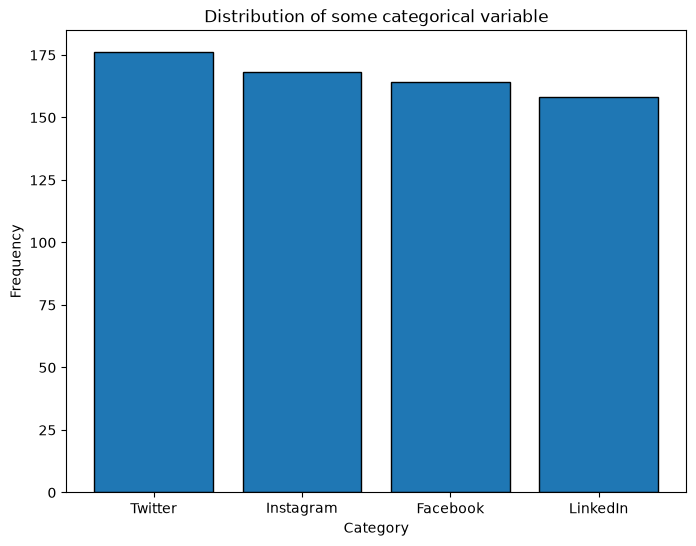

In [33]:
import numpy as np
import matplotlib.pyplot as plt
 
data = df_clean['platform']                  
 
frequencies = data.value_counts()
proportion = data.value_counts(normalize=True)
print(frequencies)
print(proportion)
 
 
plt.figure(figsize=(8, 6))                      
plt.bar(frequencies.index, frequencies.values, edgecolor='black')  
plt.title('Distribution of some categorical variable')
plt.xlabel("Category")
plt.ylabel("Frequency")
plt.xticks(frequencies.index)                  
plt.show()

Average impressions: 109755.67717717717


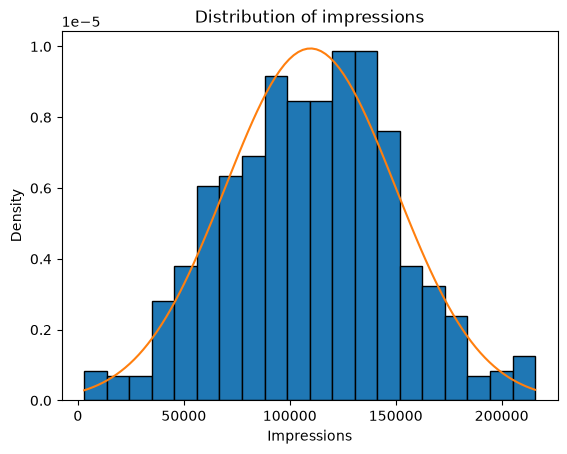

In [34]:
from scipy.stats import norm

data = df_clean["impressions"]

mean = data.mean()
std = data.std()

print("Average impressions:", mean)

plt.hist(data, bins=20, density=True, edgecolor="black")

x = np.linspace(data.min(), data.max(), 100)
plt.plot(x, norm.pdf(x, mean, std))

plt.title("Distribution of impressions")
plt.xlabel("Impressions")
plt.ylabel("Density")
plt.show()

In [35]:
import numpy as np

for platform in ["Instagram", "Facebook", "LinkedIn", "Twitter"]:
    data = df_clean[df_clean["platform"] == platform]["reach"]

    print(platform)
    print("Mean:", np.mean(data))
    print("Median:", np.median(data))
    print("Minimum:", np.min(data))
    print("Maximum:", np.max(data))
    print("Range:", np.max(data) - np.min(data))
    print("Variance:", np.var(data, ddof=1))
    print("Standard deviation:", np.std(data, ddof=1))
    print()

Instagram
Mean: 42653.01190476191
Median: 43998.5
Minimum: 1395.0
Maximum: 88062.0
Range: 86667.0
Variance: 297548300.70644426
Standard deviation: 17249.58842136369

Facebook
Mean: 38577.993902439026
Median: 38069.5
Minimum: 3736.0
Maximum: 77304.0
Range: 73568.0
Variance: 182066432.19014663
Standard deviation: 13493.199479372808

LinkedIn
Mean: 17060.13924050633
Median: 16651.0
Minimum: 684.0
Maximum: 36981.0
Range: 36297.0
Variance: 54543845.77666693
Standard deviation: 7385.380543795081

Twitter
Mean: 26994.670454545456
Median: 27396.5
Minimum: 2992.0
Maximum: 57542.0
Range: 54550.0
Variance: 102241771.65077925
Standard deviation: 10111.467334209177



**Opdracht2**


In [36]:
df_clean["engagement_rate"] = df_clean["engagements"] / df_clean["impressions"]

print("Overall average:", np.mean(df_clean["engagement_rate"]))

for platform in ["Instagram", "Facebook", "LinkedIn", "Twitter"]:
    data = df_clean[df_clean["platform"] == platform]["engagement_rate"]
    print(platform, np.mean(data))

Overall average: 0.07994007863083223
Instagram 0.09858576015237257
Facebook 0.0774199564427391
LinkedIn 0.06639997697232762
Twitter 0.07664554229715174


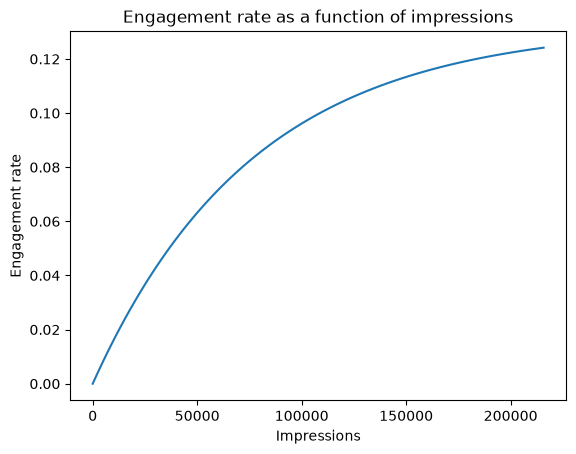

In [37]:
a = np.max(df_clean["engagement_rate"])
b = 0.000013

I = np.linspace(0, np.max(df_clean["impressions"]), 100)
E = a * (1 - np.exp(-b * I))

plt.plot(I, E)
plt.title("Engagement rate as a function of impressions")
plt.xlabel("Impressions")
plt.ylabel("Engagement rate")
plt.show()



In [38]:
import sympy as sp

I, a, b = sp.symbols("I a b", positive=True)

E = a * (1 - sp.exp(-b * I))
derivative = sp.diff(E, I)

print(derivative)

a*b*exp(-I*b)


The positive first derivative, E'(I), means that the engagement rate increases as impressions, I, increase. However, E'(I) becomes smaller as I grows, so each additional impression produces a smaller increase in engagement rate. Eventually, the curve levels off as the engagement rate approaches its maximum value, a.

In [39]:
for platform in ["Instagram", "Facebook", "LinkedIn", "Twitter"]:
    data = df_clean[df_clean["platform"] == platform]["ctr"]

    print(platform)
    print("Mean:", np.mean(data))
    print("Standard deviation:", np.std(data, ddof=1))
    print()

Instagram
Mean: 0.07497804876210801
Standard deviation: 0.005192801251959928

Facebook
Mean: 0.060080321291830996
Standard deviation: 0.005010267008218301

LinkedIn
Mean: 0.02549998216674332
Standard deviation: 0.005017236344861996

Twitter
Mean: 0.04516546494667
Standard deviation: 0.004714803435861191



**Assignment 3**

In [40]:
from scipy.stats import f_oneway
from statsmodels.stats.multicomp import pairwise_tukeyhsd

instagram = df_clean[df_clean["platform"] == "Instagram"]["ctr"]
facebook = df_clean[df_clean["platform"] == "Facebook"]["ctr"]
linkedin = df_clean[df_clean["platform"] == "LinkedIn"]["ctr"]
twitter = df_clean[df_clean["platform"] == "Twitter"]["ctr"]

statistic, p_value = f_oneway(instagram, facebook, linkedin, twitter)

print("ANOVA p-value:", p_value)

ANOVA p-value: 0.0


In [41]:
tukey = pairwise_tukeyhsd(
    df_clean["ctr"],
    df_clean["platform"],
    alpha=0.05
)

print(tukey)

   Multiple Comparison of Means - Tukey HSD, FWER=0.05   
  group1    group2  meandiff p-adj  lower   upper  reject
---------------------------------------------------------
 Facebook Instagram   0.0149   0.0  0.0135  0.0163   True
 Facebook  LinkedIn  -0.0346   0.0  -0.036 -0.0331   True
 Facebook   Twitter  -0.0149   0.0 -0.0163 -0.0135   True
Instagram  LinkedIn  -0.0495   0.0 -0.0509 -0.0481   True
Instagram   Twitter  -0.0298   0.0 -0.0312 -0.0284   True
 LinkedIn   Twitter   0.0197   0.0  0.0183  0.0211   True
---------------------------------------------------------


*Assignment 3b*

In [42]:
from scipy.stats import ttest_ind

linkedin = df_clean[df_clean["platform"] == "LinkedIn"]["cvr"]
twitter = df_clean[df_clean["platform"] == "Twitter"]["cvr"]

print("LinkedIn mean:", np.mean(linkedin))
print("Twitter mean:", np.mean(twitter))

print(ttest_ind(linkedin, twitter, alternative="greater"))

LinkedIn mean: 0.08983607707674171
Twitter mean: 0.030004989513338666
TtestResult(statistic=np.float64(307.97186570138274), pvalue=np.float64(0.0), df=np.float64(332.0))


*Assignment 3c*

In [43]:
from scipy.stats import t, sem

data = df_clean["cvr"]

n = len(data)
mean = np.mean(data)
std_err = sem(data)

interval = t.interval(confidence=0.95, df=n-1, loc=mean, scale=std_err)

print("95% confidence interval:", interval)

95% confidence interval: (np.float64(0.062391044071960916), np.float64(0.06574313282740157))


For example, if the output is (0.075, 0.082), multiply each number by 100 to get 7.5% and 8.2% for all adds.

*Assignment 3d*

In [44]:
from scipy.stats import norm

mean = 0.0812
std = 0.001
z = norm.ppf(0.90)
x = mean + z * std

print("Z-score:", z)
print("Top 10% CVR x (%):", x * 100)

Z-score: 1.2815515655446004
Top 10% CVR x (%): 8.24815515655446


**Assignment 4**

In [46]:
successful_ads = (df_clean["engagement_rate"] > 0.11).sum()
total_ads = len(df_clean)

probability = successful_ads / total_ads

print("Successful ads:", successful_ads)
print("Total ads:", total_ads)
print("Probability (%):", probability * 100)

Successful ads: 65
Total ads: 666
Probability (%): 9.75975975975976


*Assignment 4b*

In [47]:
instagram = df_clean[df_clean["platform"] == "Instagram"]

instagram_success = (instagram["engagement_rate"] > 0.11).sum()
instagram_probability = instagram_success / len(instagram)

print("Instagram probability (%):", instagram_probability * 100)

Instagram probability (%): 38.69047619047619


In [48]:
facebook = df_clean[df_clean["platform"] == "Facebook"]

facebook_success = (facebook["engagement_rate"] > 0.11).sum()
facebook_probability = facebook_success / len(facebook)

print("Facebook probability (%):", facebook_probability * 100)

Facebook probability (%): 0.0


In [49]:
instagram_probability - facebook_probability

np.float64(0.3869047619047619)

this means that instagram's probability is higher

*Assignment 4C*

In [ ]:
total_ads = 666
successful_last_year = 65
not_successful_last_year = total_ads - successful_last_year

successful_this_year = 2
not_successful_this_year = 48

prior_mean = successful_last_year / total_ads

total_successful = successful_last_year + successful_this_year
total_unsuccessful = not_successful_last_year + not_successful_this_year

posterior_mean = total_successful / (total_successful + total_unsuccessful)

print("Prior mean (%):", prior_mean * 100)
print("Posterior mean (%):", posterior_mean * 100)

Prior mean (%): 9.75975975975976
Posterior mean (%): 9.35754189944134


The prior distribution is Beta(68, 603). Adding this year’s 2 successful and 48 unsuccessful ads gives a posterior distribution of Beta(70, 651). The estimated probability of a successful ad decreases from 10.13% to 9.71%. The update therefore does not support the manager’s suspicion that the probability has increased.

*Assignment 4d*

In [3]:
from scipy.stats import beta
 
1 - beta.cdf(x=0.11, a=(65+2), b=(601+48))
 

np.float64(0.07060829645706068)

**Assignment 5**

The derivative is: 1215.36 - 101.28*t
The derivative is 0 on day: [12.0000000000000]


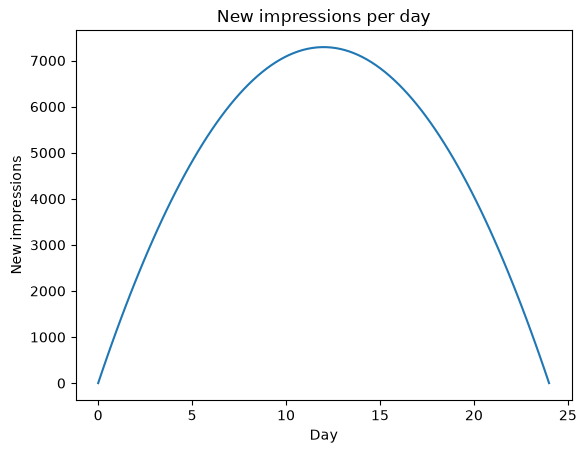

In [4]:
from sympy import symbols, diff, solve

import numpy as np

import matplotlib.pyplot as plt

t = symbols('t')

f = -50.64 * t**2 + 1215.36 * t

derivative = diff(f)

print('The derivative is:', derivative)

day = solve(derivative, t)

print('The derivative is 0 on day:', day)

days = np.linspace(0, 24, 100)

plt.plot(days, -50.64 * days**2 + 1215.36 * days)

plt.title('New impressions per day')

plt.xlabel('Day')

plt.ylabel('New impressions')

plt.show()

In [6]:
t = 12
-50.64 * t**2 + 1215.36 * t

7292.16

*Assignment 5b*

In [7]:
from sympy import symbols, integrate

t = symbols("t")
f = -50.64 * t**2 + 1215.36 * t

total = integrate(f, (t, 0, 12))

print("Total impressions until day 12:", total)

Total impressions until day 12: 58337.2800000000
